In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

tips = pd.read_csv("tips.csv")

X = tips[["total_bill"]]
y = tips["tip"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [2]:
len(X_train)

170

We hold out 30% of the data so the model can be tested without any prior knowledge. If the model already knew the data, it would already know the answers and the score would be high. To ensure proper testing accuracy that the model is functioning and not just saying answers it already saw, we use unseen data to test how it performs on new data.

In [3]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print(model.coef_)
print(model.intercept_)

[0.10889371]
0.8769576391532707


Each extra dollar of bill adds about $0.11 of tip.

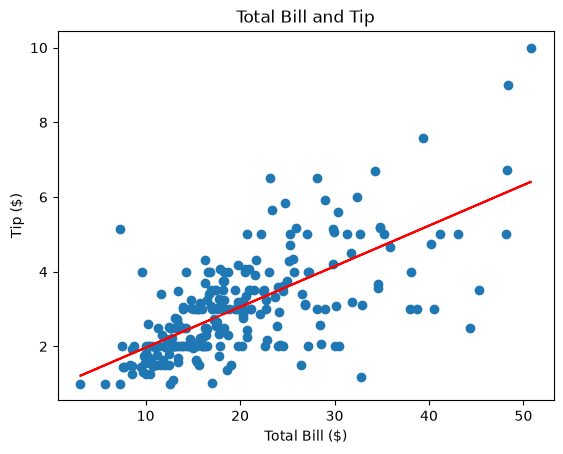

In [4]:
import matplotlib.pyplot as plt

plt.scatter(X, y)
plt.plot(X, model.predict(X), color="red")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.title("Total Bill and Tip")
plt.show()

In [5]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
print(len(X))
print(len(X_train))

150
105


In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print(knn.score(X_test, y_test))

1.0


1.0


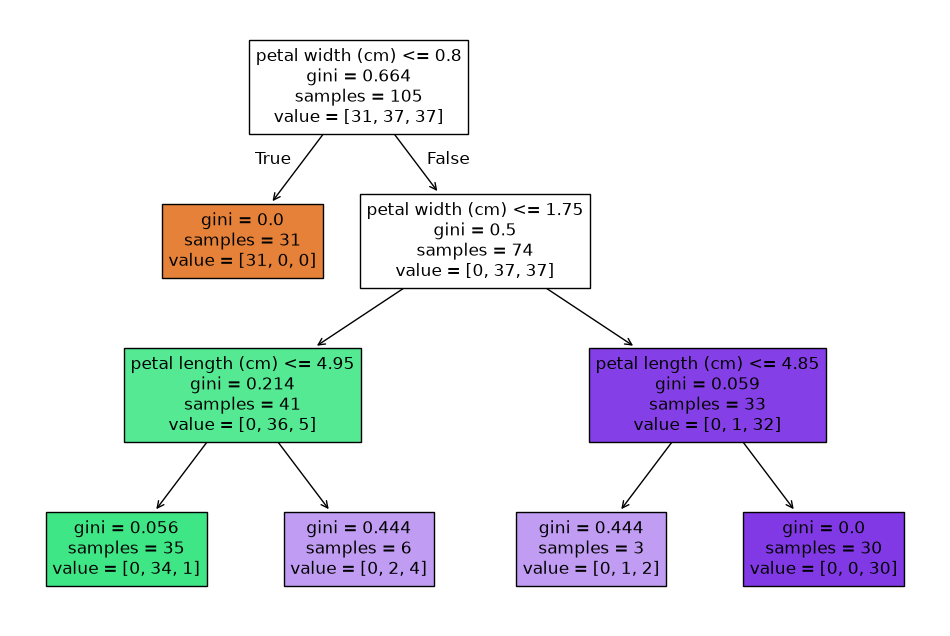

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree = DecisionTreeClassifier(max_depth=3)
tree.fit(X_train, y_train)

print(tree.score(X_test, y_test))

plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=iris.feature_names, filled=True)
plt.show()

The decison tree first checks if the petal is less than or greater than .8. From there is creates the first decision based on a true/false.

In [8]:
unlimited_tree = DecisionTreeClassifier()
unlimited_tree.fit(X_train, y_train)

scores = pd.DataFrame({
    "Model": ["Shallow tree", "Unlimited tree"],
    "Train score": [
        tree.score(X_train, y_train),
        unlimited_tree.score(X_train, y_train)
    ],
    "Test score": [
        tree.score(X_test, y_test),
        unlimited_tree.score(X_test, y_test)]})

scores

,Model,Train score,Test score
0,Shallow tree,0.961905,1.0
1,Unlimited tree,1.000000,1.0


The unlimited tree had a higher train score than the shallow tree but both had the same test score so having the tree to grow without a max did not change its performance with the new data.

In [9]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names)

prediction = tree.predict(new_flower)

print(iris.target_names[prediction[0]])

setosa


The regression model predicted that the tip amount based from the total bill would add about .11 for each additional dollar. The kNN and deceision tree classification models predicted the flower species from measurements. I would choose the shallow tree decision tree because I like how the decisions are easy to follow. The shallow tree's test score is 1.0. The model could fail if the measurements were incorrect or if they differed too much from the training data. If the model were about people a bias could occur if the training data excluded certain groups or important information used to make decisions.

AI USE:
-help install scikit
-help understand the model scores
- help with deeper understanding and explanation of decision tree boxes

https://github.com/e-flores-data/cs82a-portfolio